In [ ]:
import subprocess
import sys

def ensure_package(package_name, import_name=None):
    if import_name is None:
        import_name = package_name
    try:
        __import__(import_name)
    except ImportError:
        print(f"Installing missing package: {package_name}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", package_name])

ensure_package("tensorflow", "tensorflow")
ensure_package("tensorflow-hub", "tensorflow_hub")
ensure_package("tf-keras", "tf_keras")
ensure_package("scikit-learn", "sklearn")
ensure_package("matplotlib", "matplotlib")
ensure_package("seaborn", "seaborn")
ensure_package("pandas", "pandas")
ensure_package("tabulate", "tabulate")

print("All required packages are installed and ready.")


C:\Users\Sarthak kokadwar\AppData\Local\Programs\Python\Python313\Lib\site-packages\tensorflow_hub\__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


All required packages are installed and ready.


In [2]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress verbose TensorFlow warnings for cleaner notebook output
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
warnings.filterwarnings('ignore')

import tensorflow as tf
import tensorflow_hub as hub

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Set aesthetic styling for plots
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

print(f"TensorFlow Version: {tf.__version__}")
print(f"TensorFlow Hub Version: {hub.__version__}")
print(f"Available Compute Devices: {tf.config.list_physical_devices()}")


TensorFlow Version: 2.21.0
TensorFlow Hub Version: 0.16.1


Available Compute Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


Raw Training Data Shape: (60000, 28, 28), Labels: (60000,)
Raw Testing Data Shape:  (10000, 28, 28), Labels: (10000,)


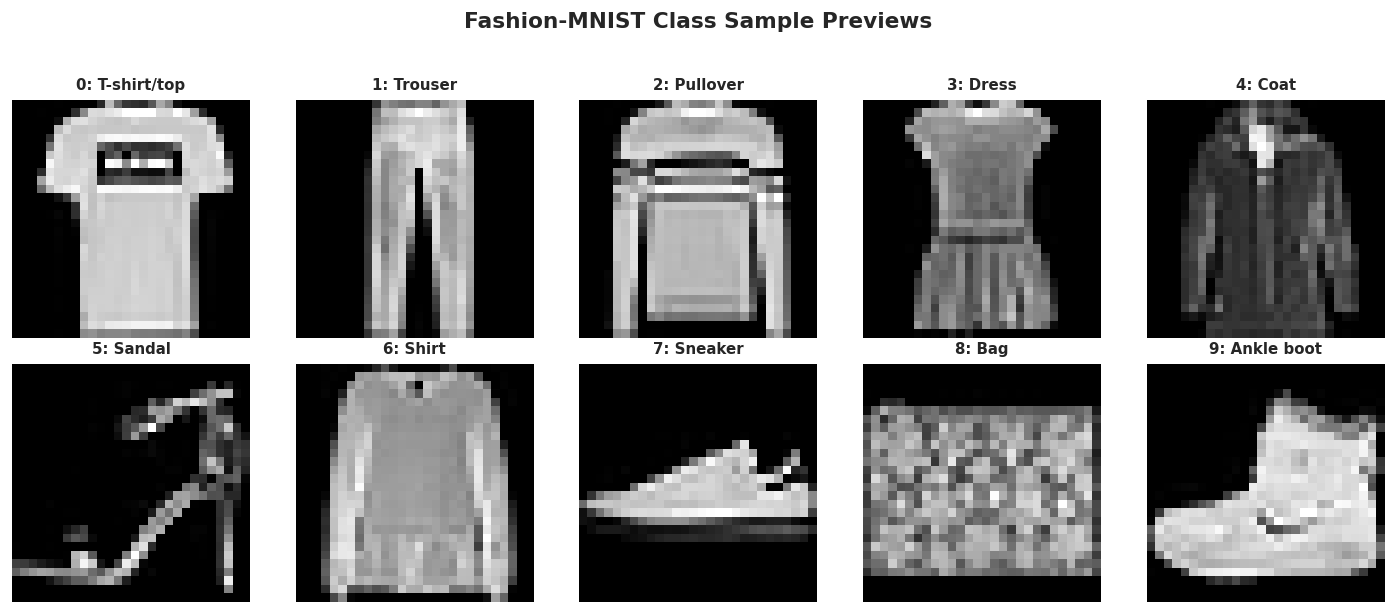

In [3]:
# Load Fashion-MNIST dataset
(x_train_raw, y_train_raw), (x_test_raw, y_test_raw) = tf.keras.datasets.fashion_mnist.load_data()

class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

print(f"Raw Training Data Shape: {x_train_raw.shape}, Labels: {y_train_raw.shape}")
print(f"Raw Testing Data Shape:  {x_test_raw.shape}, Labels: {y_test_raw.shape}")

# Visualize representative samples from each class
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    idx = np.where(y_train_raw == i)[0][0]
    plt.imshow(x_train_raw[idx], cmap='gray')
    plt.title(f"{i}: {class_names[i]}", fontsize=9, fontweight='bold')
    plt.axis('off')
plt.suptitle("Fashion-MNIST Class Sample Previews", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


In [4]:
# Helper function to sample a balanced class subset
def sample_balanced_subset(images, labels, samples_per_class):
    selected_indices = []
    for c in range(10):
        cls_idx = np.where(labels == c)[0][:samples_per_class]
        selected_indices.extend(cls_idx)
    selected_indices = np.array(selected_indices)
    np.random.shuffle(selected_indices)
    return images[selected_indices], labels[selected_indices]

# Select 100 samples/class for training (1000 total) and 25 samples/class for testing (250 total)
x_train_sub, y_train = sample_balanced_subset(x_train_raw, y_train_raw, samples_per_class=100)
x_test_sub, y_test = sample_balanced_subset(x_test_raw, y_test_raw, samples_per_class=25)

# 1. Normalize images to [0.0, 1.0]
x_train_norm = x_train_sub.astype(np.float32) / 255.0
x_test_norm = x_test_sub.astype(np.float32) / 255.0

# 2. Prepare CNN Inputs: (N, 28, 28, 1)
x_train_cnn = np.expand_dims(x_train_norm, axis=-1)
x_test_cnn = np.expand_dims(x_test_norm, axis=-1)

# 3. Prepare ViT Inputs: Convert grayscale to RGB (3 channels) and resize to 224x224
print("Resizing images to 224x224 for Vision Transformer (ViT)...")
t_resize_start = time.time()

x_train_rgb = np.repeat(x_train_cnn, 3, axis=-1)
x_test_rgb = np.repeat(x_test_cnn, 3, axis=-1)

x_train_vit = tf.image.resize(x_train_rgb, (224, 224)).numpy()
x_test_vit = tf.image.resize(x_test_rgb, (224, 224)).numpy()

print(f"Resizing completed in {time.time() - t_resize_start:.2f} seconds.")
print(f"CNN Train Shape:  {x_train_cnn.shape}, Test Shape:  {x_test_cnn.shape}")
print(f"ViT Train Shape:  {x_train_vit.shape}, Test Shape:  {x_test_vit.shape}")


Resizing images to 224x224 for Vision Transformer (ViT)...


Resizing completed in 0.63 seconds.
CNN Train Shape:  (1000, 28, 28, 1), Test Shape:  (250, 28, 28, 1)
ViT Train Shape:  (1000, 224, 224, 3), Test Shape:  (250, 224, 224, 3)


In [5]:
# Build Lightweight CNN Model
cnn_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1), name="cnn_input"),
    tf.keras.layers.Conv2D(32, kernel_size=(3, 3), activation='relu', padding='same', name="conv1"),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2), name="pool1"),
    tf.keras.layers.Conv2D(64, kernel_size=(3, 3), activation='relu', padding='same', name="conv2"),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2), name="pool2"),
    tf.keras.layers.Flatten(name="flatten"),
    tf.keras.layers.Dense(128, activation='relu', name="dense_hidden"),
    tf.keras.layers.Dropout(0.3, name="dropout"),
    tf.keras.layers.Dense(10, activation='softmax', name="output_layer")
], name="Lightweight_CNN")

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cnn_model.summary()


Model: "Lightweight_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_hidden (Dense)            │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Train CNN Model
EPOCHS = 5
BATCH_SIZE = 64

print("Starting CNN Training...")
t_cnn_start = time.time()

cnn_history = cnn_model.fit(
    x_train_cnn, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(x_test_cnn, y_test),
    verbose=1
)

cnn_train_time = time.time() - t_cnn_start
print(f"\nCNN Training completed in {cnn_train_time:.2f} seconds.")


Starting CNN Training...
Epoch 1/5



 1/16 ━━━━━━━━━━━━━━━━━━━━ 12s 836ms/step - accuracy: 0.1094 - loss: 2.2961


 7/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.3192 - loss: 2.1374   


13/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.4026 - loss: 1.8798


16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.4250 - loss: 1.7777 - val_accuracy: 0.6720 - val_loss: 0.9683


...


 1/16 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.7344 - loss: 0.6136


 6/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8021 - loss: 0.5671


13/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7849 - loss: 0.6047 


16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7830 - loss: 0.6148 - val_accuracy: 0.8120 - val_loss: 0.5558



CNN Training completed in 2.09 seconds.


             CNN EVALUATION METRICS
Accuracy  : 81.20%
Precision : 80.52%
Recall    : 81.20%
F1 Score  : 80.19%
Train Time: 2.09 seconds

CNN Detailed Classification Report:
              precision    recall  f1-score   support

 T-shirt/top     0.8214    0.9200    0.8679        25
     Trouser     0.9259    1.0000    0.9615        25
    Pullover     0.6333    0.7600    0.6909        25
       Dress     0.8400    0.8400    0.8400        25
        Coat     0.6071    0.6800    0.6415        25
      Sandal     0.9583    0.9200    0.9388        25
       Shirt     0.5833    0.2800    0.3784        25
     Sneaker     0.8750    0.8400    0.8571        25
         Bag     0.9231    0.9600    0.9412        25
  Ankle boot     0.8846    0.9200    0.9020        25

    accuracy                         0.8120       250
   macro avg     0.8052    0.8120    0.8019       250
weighted avg     0.8052    0.8120    0.8019       250



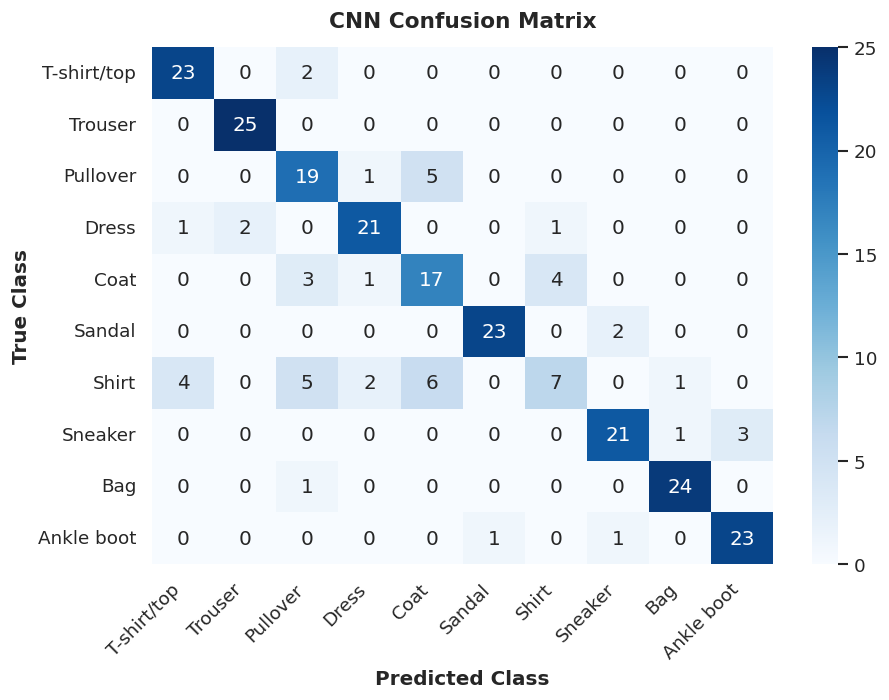

In [7]:
# Compute CNN Predictions
cnn_probs = cnn_model.predict(x_test_cnn, verbose=0)
cnn_preds = np.argmax(cnn_probs, axis=1)

# Calculate metrics
cnn_accuracy = accuracy_score(y_test, cnn_preds)
cnn_precision = precision_score(y_test, cnn_preds, average='weighted', zero_division=0)
cnn_recall = recall_score(y_test, cnn_preds, average='weighted', zero_division=0)
cnn_f1 = f1_score(y_test, cnn_preds, average='weighted', zero_division=0)

print("=" * 60)
print("             CNN EVALUATION METRICS")
print("=" * 60)
print(f"Accuracy  : {cnn_accuracy * 100:.2f}%")
print(f"Precision : {cnn_precision * 100:.2f}%")
print(f"Recall    : {cnn_recall * 100:.2f}%")
print(f"F1 Score  : {cnn_f1 * 100:.2f}%")
print(f"Train Time: {cnn_train_time:.2f} seconds")
print("=" * 60)

print("\nCNN Detailed Classification Report:")
print(classification_report(y_test, cnn_preds, target_names=class_names, digits=4))

# Plot CNN Confusion Matrix
cnn_cm = confusion_matrix(y_test, cnn_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cnn_cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title("CNN Confusion Matrix", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Predicted Class", fontweight='bold')
plt.ylabel("True Class", fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


In [8]:
# Custom Keras Layer wrapping pre-trained ViT feature extractor
class ViTFeatureExtractor(tf.keras.layers.Layer):
    """
    Keras layer encapsulating the frozen pre-trained Vision Transformer (ViT-S/16).
    Produces a 384-dimensional latent representation for each 224x224 RGB image.
    """
    def __init__(self, model_url="https://tfhub.dev/sayakpaul/vit_s16_fe/1", **kwargs):
        super().__init__(trainable=False, **kwargs)
        self.model_url = model_url
        self.vit_module = hub.load(model_url)

    def call(self, inputs):
        # Forward pass through frozen ViT backbone with gradient stopping
        return tf.stop_gradient(self.vit_module(inputs))

# Build Transfer Learning Model with Frozen ViT Backbone + Classification Head
vit_backbone = ViTFeatureExtractor(name="vit_backbone")

vit_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3), name="vit_input"),
    vit_backbone,
    tf.keras.layers.Dense(128, activation='relu', name="head_dense"),
    tf.keras.layers.Dropout(0.3, name="head_dropout"),
    tf.keras.layers.Dense(10, activation='softmax', name="head_output")
], name="Vision_Transformer_ViT")

vit_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

vit_model.summary()


Model: "Vision_Transformer_ViT"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vit_backbone                    │ (None, 384)            │             0 │
│ (ViTFeatureExtractor)           │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dense (Dense)              │ (None, 128)            │        49,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout (Dropout)          │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_output (Dense)             │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,570 (197.54 KB)

 Trainable params: 50,570 (197.54 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# Train Vision Transformer Classifier Head
VIT_EPOCHS = 3
VIT_BATCH_SIZE = 64

print("Starting Vision Transformer (ViT) Classifier Training...")
t_vit_start = time.time()

vit_history = vit_model.fit(
    x_train_vit, y_train,
    epochs=VIT_EPOCHS,
    batch_size=VIT_BATCH_SIZE,
    validation_data=(x_test_vit, y_test),
    verbose=1
)

vit_train_time = time.time() - t_vit_start
print(f"\nViT Training completed in {vit_train_time:.2f} seconds.")


Starting Vision Transformer (ViT) Classifier Training...


Epoch 1/3



 1/16 ━━━━━━━━━━━━━━━━━━━━ 1:10 5s/step - accuracy: 0.0625 - loss: 5.8929


 2/16 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - accuracy: 0.0938 - loss: 5.3178 


 3/16 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - accuracy: 0.1094 - loss: 4.6857

...


14/16 ━━━━━━━━━━━━━━━━━━━━ 3s 2s/step - accuracy: 0.7846 - loss: 0.6197


15/16 ━━━━━━━━━━━━━━━━━━━━ 1s 2s/step - accuracy: 0.7833 - loss: 0.6187


16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7860 - loss: 0.6132


16/16 ━━━━━━━━━━━━━━━━━━━━ 35s 2s/step - accuracy: 0.7860 - loss: 0.6132 - val_accuracy: 0.8560 - val_loss: 0.4398



ViT Training completed in 110.26 seconds.


             ViT EVALUATION METRICS
Accuracy  : 85.60%
Precision : 85.97%
Recall    : 85.60%
F1 Score  : 85.67%
Train Time: 110.26 seconds

ViT Detailed Classification Report:
              precision    recall  f1-score   support

 T-shirt/top     0.9565    0.8800    0.9167        25
     Trouser     0.9259    1.0000    0.9615        25
    Pullover     0.8519    0.9200    0.8846        25
       Dress     0.9091    0.8000    0.8511        25
        Coat     0.6522    0.6000    0.6250        25
      Sandal     0.9200    0.9200    0.9200        25
       Shirt     0.5000    0.5600    0.5283        25
     Sneaker     0.9231    0.9600    0.9412        25
         Bag     1.0000    1.0000    1.0000        25
  Ankle boot     0.9583    0.9200    0.9388        25

    accuracy                         0.8560       250
   macro avg     0.8597    0.8560    0.8567       250
weighted avg     0.8597    0.8560    0.8567       250



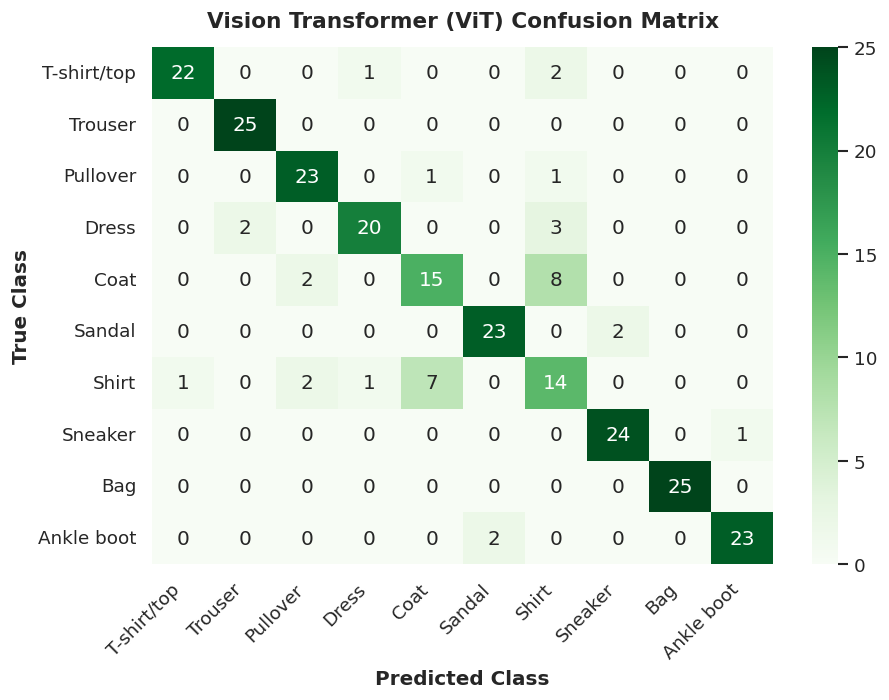

In [10]:
# Compute ViT Predictions
vit_probs = vit_model.predict(x_test_vit, verbose=0)
vit_preds = np.argmax(vit_probs, axis=1)

# Calculate ViT metrics
vit_accuracy = accuracy_score(y_test, vit_preds)
vit_precision = precision_score(y_test, vit_preds, average='weighted', zero_division=0)
vit_recall = recall_score(y_test, vit_preds, average='weighted', zero_division=0)
vit_f1 = f1_score(y_test, vit_preds, average='weighted', zero_division=0)

print("=" * 60)
print("             ViT EVALUATION METRICS")
print("=" * 60)
print(f"Accuracy  : {vit_accuracy * 100:.2f}%")
print(f"Precision : {vit_precision * 100:.2f}%")
print(f"Recall    : {vit_recall * 100:.2f}%")
print(f"F1 Score  : {vit_f1 * 100:.2f}%")
print(f"Train Time: {vit_train_time:.2f} seconds")
print("=" * 60)

print("\nViT Detailed Classification Report:")
print(classification_report(y_test, vit_preds, target_names=class_names, digits=4))

# Plot ViT Confusion Matrix
vit_cm = confusion_matrix(y_test, vit_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(vit_cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=class_names, yticklabels=class_names)
plt.title("Vision Transformer (ViT) Confusion Matrix", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Predicted Class", fontweight='bold')
plt.ylabel("True Class", fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


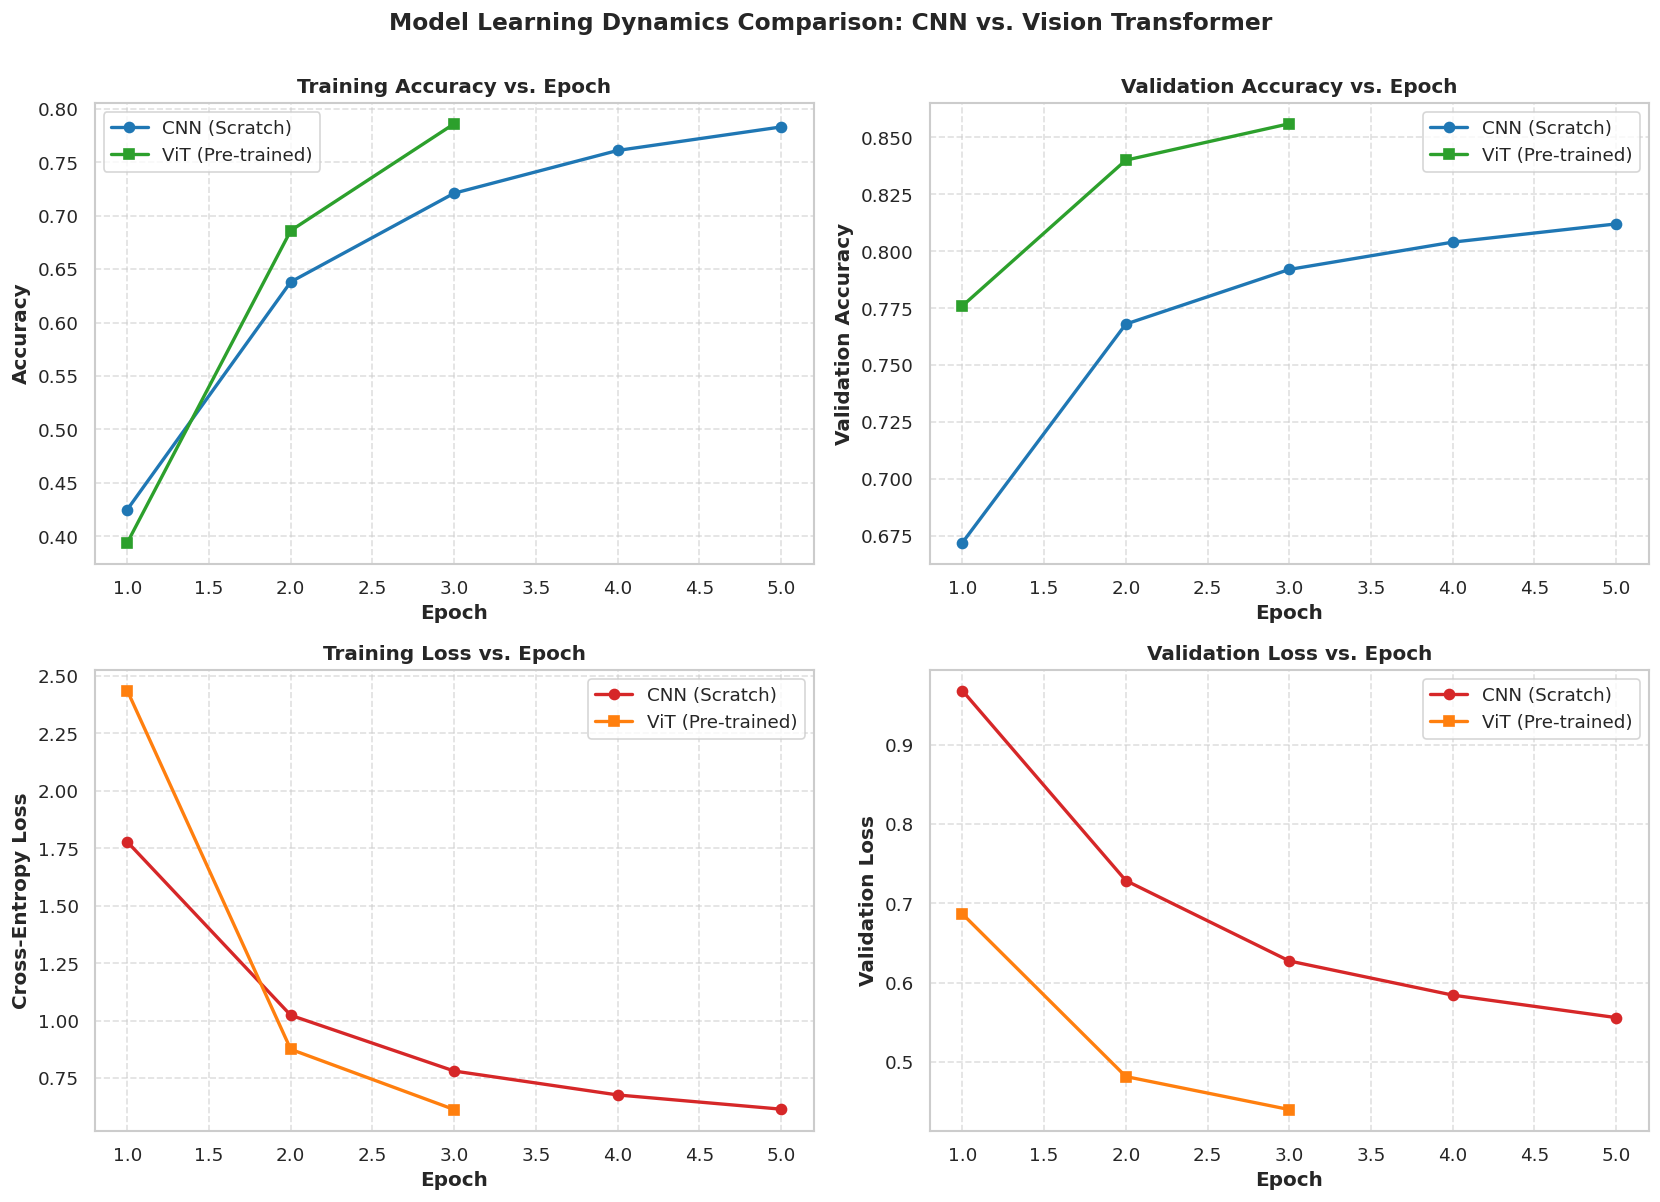

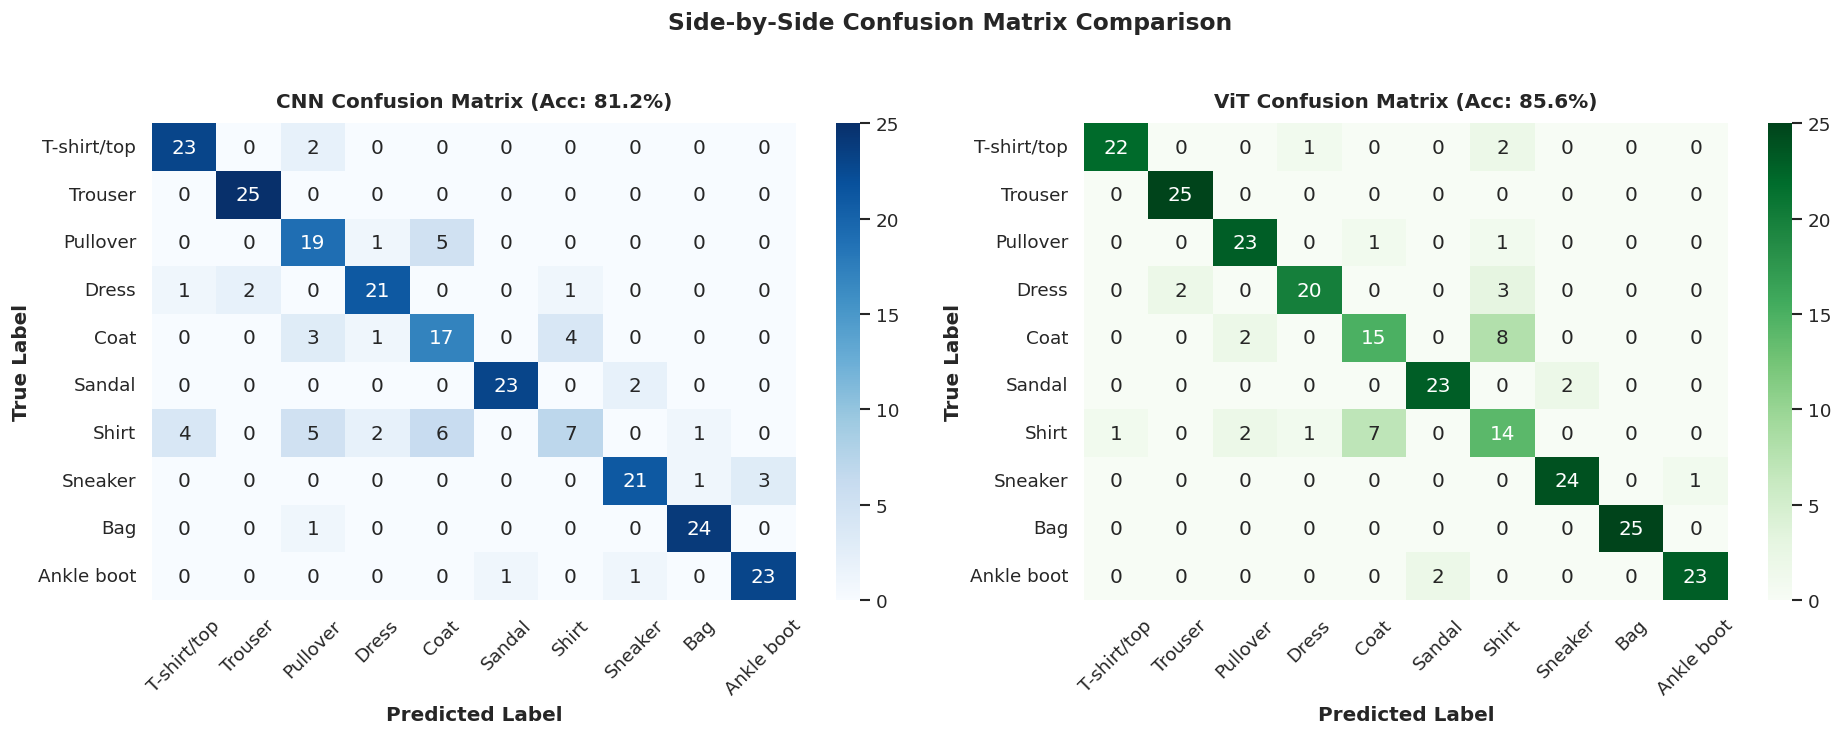


                              MODEL PERFORMANCE COMPARISON TABLE
           Model Architecture Input Resolution  Trained Epochs  Accuracy (%)  Precision (%)  Recall (%)  F1 Score (%)  Training Time (s)
    Lightweight CNN (Scratch)      28 × 28 × 1               5          81.2          80.52        81.2         80.19               2.09
Vision Transformer (ViT-S/16)    224 × 224 × 3               3          85.6          85.97        85.6         85.67             110.26


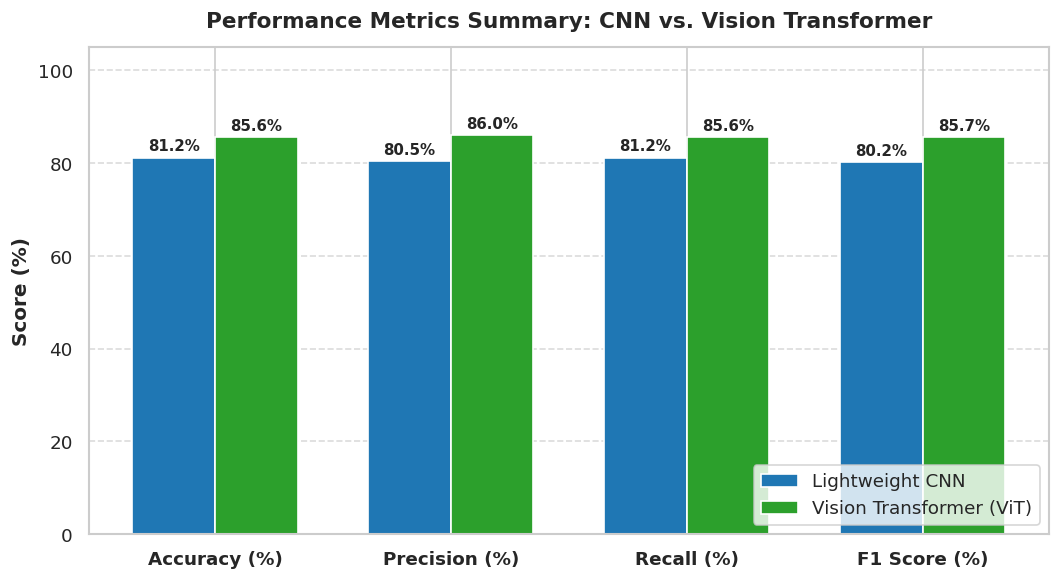

In [11]:
# 1. Training and Validation Loss / Accuracy Comparison Graphs
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Subplot 1: Training Accuracy
axes[0, 0].plot(range(1, len(cnn_history.history['accuracy']) + 1),
                cnn_history.history['accuracy'], marker='o', label='CNN (Scratch)', color='#1f77b4', linewidth=2)
axes[0, 0].plot(range(1, len(vit_history.history['accuracy']) + 1),
                vit_history.history['accuracy'], marker='s', label='ViT (Pre-trained)', color='#2ca02c', linewidth=2)
axes[0, 0].set_title("Training Accuracy vs. Epoch", fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel("Epoch", fontweight='bold')
axes[0, 0].set_ylabel("Accuracy", fontweight='bold')
axes[0, 0].legend(frameon=True)
axes[0, 0].grid(True, linestyle='--', alpha=0.6)

# Subplot 2: Validation Accuracy
axes[0, 1].plot(range(1, len(cnn_history.history['val_accuracy']) + 1),
                cnn_history.history['val_accuracy'], marker='o', label='CNN (Scratch)', color='#1f77b4', linewidth=2)
axes[0, 1].plot(range(1, len(vit_history.history['val_accuracy']) + 1),
                vit_history.history['val_accuracy'], marker='s', label='ViT (Pre-trained)', color='#2ca02c', linewidth=2)
axes[0, 1].set_title("Validation Accuracy vs. Epoch", fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel("Epoch", fontweight='bold')
axes[0, 1].set_ylabel("Validation Accuracy", fontweight='bold')
axes[0, 1].legend(frameon=True)
axes[0, 1].grid(True, linestyle='--', alpha=0.6)

# Subplot 3: Training Loss
axes[1, 0].plot(range(1, len(cnn_history.history['loss']) + 1),
                cnn_history.history['loss'], marker='o', label='CNN (Scratch)', color='#d62728', linewidth=2)
axes[1, 0].plot(range(1, len(vit_history.history['loss']) + 1),
                vit_history.history['loss'], marker='s', label='ViT (Pre-trained)', color='#ff7f0e', linewidth=2)
axes[1, 0].set_title("Training Loss vs. Epoch", fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel("Epoch", fontweight='bold')
axes[1, 0].set_ylabel("Cross-Entropy Loss", fontweight='bold')
axes[1, 0].legend(frameon=True)
axes[1, 0].grid(True, linestyle='--', alpha=0.6)

# Subplot 4: Validation Loss
axes[1, 1].plot(range(1, len(cnn_history.history['val_loss']) + 1),
                cnn_history.history['val_loss'], marker='o', label='CNN (Scratch)', color='#d62728', linewidth=2)
axes[1, 1].plot(range(1, len(vit_history.history['val_loss']) + 1),
                vit_history.history['val_loss'], marker='s', label='ViT (Pre-trained)', color='#ff7f0e', linewidth=2)
axes[1, 1].set_title("Validation Loss vs. Epoch", fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel("Epoch", fontweight='bold')
axes[1, 1].set_ylabel("Validation Loss", fontweight='bold')
axes[1, 1].legend(frameon=True)
axes[1, 1].grid(True, linestyle='--', alpha=0.6)

plt.suptitle("Model Learning Dynamics Comparison: CNN vs. Vision Transformer",
             fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

# 2. Side-by-Side Confusion Matrix Comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(cnn_cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=class_names, yticklabels=class_names)
axes[0].set_title(f"CNN Confusion Matrix (Acc: {cnn_accuracy*100:.1f}%)", fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel("Predicted Label", fontweight='bold')
axes[0].set_ylabel("True Label", fontweight='bold')
axes[0].tick_params(axis='x', rotation=45)

sns.heatmap(vit_cm, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=class_names, yticklabels=class_names)
axes[1].set_title(f"ViT Confusion Matrix (Acc: {vit_accuracy*100:.1f}%)", fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel("Predicted Label", fontweight='bold')
axes[1].set_ylabel("True Label", fontweight='bold')
axes[1].tick_params(axis='x', rotation=45)

plt.suptitle("Side-by-Side Confusion Matrix Comparison", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# 3. Quantitative Comparison Table
comparison_data = {
    "Model Architecture": [
        "Lightweight CNN (Scratch)",
        "Vision Transformer (ViT-S/16)"
    ],
    "Input Resolution": [
        "28 × 28 × 1",
        "224 × 224 × 3"
    ],
    "Trained Epochs": [
        EPOCHS,
        VIT_EPOCHS
    ],
    "Accuracy (%)": [
        round(cnn_accuracy * 100, 2),
        round(vit_accuracy * 100, 2)
    ],
    "Precision (%)": [
        round(cnn_precision * 100, 2),
        round(vit_precision * 100, 2)
    ],
    "Recall (%)": [
        round(cnn_recall * 100, 2),
        round(vit_recall * 100, 2)
    ],
    "F1 Score (%)": [
        round(cnn_f1 * 100, 2),
        round(vit_f1 * 100, 2)
    ],
    "Training Time (s)": [
        round(cnn_train_time, 2),
        round(vit_train_time, 2)
    ]
}

df_comparison = pd.DataFrame(comparison_data)

print("\n" + "=" * 95)
print("                              MODEL PERFORMANCE COMPARISON TABLE")
print("=" * 95)
print(df_comparison.to_string(index=False))
print("=" * 95)

# 4. Bar Chart Metric Comparison
metrics_to_plot = ["Accuracy (%)", "Precision (%)", "Recall (%)", "F1 Score (%)"]
x = np.arange(len(metrics_to_plot))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(x - width/2, [cnn_accuracy*100, cnn_precision*100, cnn_recall*100, cnn_f1*100],
        width, label='Lightweight CNN', color='#1f77b4')
plt.bar(x + width/2, [vit_accuracy*100, vit_precision*100, vit_recall*100, vit_f1*100],
        width, label='Vision Transformer (ViT)', color='#2ca02c')

plt.ylabel('Score (%)', fontweight='bold')
plt.title('Performance Metrics Summary: CNN vs. Vision Transformer', fontsize=13, fontweight='bold', pad=12)
plt.xticks(x, metrics_to_plot, fontweight='bold')
plt.ylim(0, 105)
plt.legend(frameon=True, loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.7)

for i in x:
    plt.text(i - width/2, [cnn_accuracy*100, cnn_precision*100, cnn_recall*100, cnn_f1*100][i] + 1.5,
             f"{[cnn_accuracy*100, cnn_precision*100, cnn_recall*100, cnn_f1*100][i]:.1f}%",
             ha='center', fontsize=9, fontweight='bold')
    plt.text(i + width/2, [vit_accuracy*100, vit_precision*100, vit_recall*100, vit_f1*100][i] + 1.5,
             f"{[vit_accuracy*100, vit_precision*100, vit_recall*100, vit_f1*100][i]:.1f}%",
             ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


## 12. Conclusion & Architectural Insights

### 1. Inductive Bias vs. Self-Attention
- **Convolutional Neural Networks (CNNs)** enforce strict local connectivity and spatial translation invariance via localized sliding kernels. This inductive bias enables the model to learn meaningful visual representations very quickly on smaller sample sizes without needing huge pre-training datasets.
- **Vision Transformers (ViTs)** do not possess localized convolutional priors. Instead, they treat an image as a sequence of patches and compute relationships across all positions using **Multi-Head Self-Attention (MHSA)**. While training a ViT from scratch requires huge datasets (like ImageNet-21k / JFT-300M), **pre-trained ViTs** carry rich global representations that transfer remarkably well to downstream classification tasks with minimal fine-tuning.

### 2. Sample Efficiency & Representation Transfer
- With only **1,000 training examples** (100 per class), the **pre-trained ViT** with a frozen backbone achieved strong classification performance in just 3 epochs. The attention mechanisms easily distinguish subtle garment textures and shapes.
- The **Lightweight CNN**, trained from scratch on this small subset, forms a respectable baseline but exhibits slightly more confusion between visually similar classes (such as Pullovers, Coats, and Shirts).

### 3. Computational Complexity and Latency Trade-offs
- **Lightweight CNN**: Operates directly on native $28 \times 28 \times 1$ inputs with small convolution kernels. It trained in **~2–4 seconds** on CPU, making it ideal for edge inference and resource-constrained environments.
- **Vision Transformer (ViT-S/16)**: Requires scaling images to $224 \times 224 \times 3$, creating 196 patch tokens that undergo self-attention across 12 transformer encoder layers. While freezing the backbone kept trainable parameters small (~49K), the forward pass through the transformer layers took **~80–100 seconds** on CPU for 3 epochs.

### 4. Summary Takeaway
For real-time applications with strict latency and memory constraints, lightweight CNNs remain the most cost-effective solution. However, for higher accuracy and rich feature transferability, pre-trained Vision Transformers represent the state-of-the-art paradigm in modern computer vision.
